# Финальный экзамен. Анализ данных в Python

Данные: записи событий матчей плей-офф НХЛ сезона 2025/2026 (файл `NHL-playoffs-2026.xlsx`).

Вся работа находится в этой тетрадке: код с комментариями, результаты и их интерпретация идут сразу под каждым пунктом. Функция рисования площадки из файла `rink.py` вставлена прямо сюда, поэтому для запуска нужен только файл с данными. В конце тетрадки есть краткие итоги по всем пунктам.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_context('notebook')
# выводим дробные числа с тремя знаками после запятой, как в примерах из задания
pd.set_option('float_format', '{:6.3f}'.format)

Функция `plot_rink()` из файла `rink.py`, выложенного вместе с заданием. Код скопирован без изменений, чтобы тетрадка работала без дополнительных файлов. Она понадобится в пункте 15.

In [2]:
# код из rink.py: рисует хоккейную площадку НХЛ (размеры в футах)
def plot_rink(annotations=False):
    plt.gcf().gca().add_artist(plt.Rectangle((-103,-44.5), 206, 89,
                                             linewidth=0,
                                             facecolor='whitesmoke',
                                             zorder=-2))
    # Lines dividing the zones
    line, = plt.plot([0,0], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='firebrick', zorder=-1)
    plt.scatter([0,0,0,0,0,0,0,0,0,0,0,0], [6,12,18,24,30,36,-6,-12,-18,-24,-30,-36], s=3, color='w', zorder=-1)
    for x in [-25, 25]:
        plt.plot([x,x], [-42.5,42.5], linewidth=4, solid_capstyle='butt', color='royalblue', zorder=-1)
    for x in [-25-64, 25+64]:
        plt.plot([x,x], [-36.75,36.75], linewidth=1, solid_capstyle='butt', color='firebrick', zorder=-1)

    # Faceoff circles
    plt.gcf().gca().add_artist(plt.Circle((0,0), 15, fill=False,
                                          linewidth=1, color='royalblue', zorder=-1))
    for x in [69, -69]:
        for y in [22, -22]:
            plt.gcf().gca().add_artist(plt.Circle((x,y), 15, fill=False,
                                                  linewidth=1, color='firebrick', zorder=-1))
            for dx in [-1,1]:
                for dy in [-1,1]:
                    plt.plot([x+dx*3,x+dx*1,x+dx*1], [y+dy*0.5,y+dy*0.5,y+dy*2], linewidth=1, color='firebrick', zorder=-1)
                    plt.plot([x+dx*1.5,x+dx*1.5], [y+dy*14.93,y+dy*16], linewidth=1, color='firebrick', zorder=-1)

    # Faceoff spots
    plt.scatter([0], [0], s=4, color='royalblue', zorder=-1)
    plt.scatter([69,69,-69,-69,-20,-20,20,20], [22,-22,22,-22,22,-22,22,-22], s=6, color='firebrick', zorder=-1)

    # Referee crease
    plt.gcf().gca().add_artist(mpatches.Arc((0,-42.5), 10, 10, angle=0, theta1=0, theta2=180,
                                            color='firebrick', zorder=-1))

    # Goalie creases
    for xscale,thoffset in [(-1,0), (1,180)]:
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [-4,-4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64),xscale*(25+64-4.47)], [4,4], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [-4,-3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.plot([xscale*(25+64-4),xscale*(25+64-4)], [4,3.3], linewidth=1, color='firebrick', zorder=-1)
        plt.gcf().gca().add_artist(mpatches.Arc((xscale*(25+64),0), 12, 12,
                                                angle=0, theta1=-41.75+thoffset, theta2=41.75+thoffset,
                                                color='firebrick', zorder=-1))
        plt.plot([xscale*(25+64),xscale*(25+64+10/3),xscale*(25+64+10/3),xscale*(25+64)], [-3,-3,3,3], linewidth=1, color='firebrick', zorder=-1)

    # Goalie trapezoids
    for dx in [-1,1]:
        for dy in [-1,1]:
            plt.plot([dx*(25+64),dx*(100)], [dy*11,dy*14], linewidth=1, color='firebrick', zorder=-1)

    # Outer boundaries
    plt.plot([-100+28,100-28], [42.5,42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100+28,100-28], [-42.5,-42.5], linewidth=1, color='black', zorder=-1)
    plt.plot([-100,-100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    plt.plot([100,100], [-42.5+28,42.5-28], linewidth=1, color='black', zorder=-1)
    # Corner arcs
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,42.5-28), 2*28, 2*28, angle=0, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,42.5-28), 2*28, 2*28, angle=90, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((-100+28,-42.5+28), 2*28, 2*28, angle=180, theta1=0, theta2=90,
                                            color='black', zorder=-1))
    plt.gcf().gca().add_artist(mpatches.Arc((100-28,-42.5+28), 2*28, 2*28, angle=-90, theta1=0, theta2=90,
                                            color='black', zorder=-1))

    if annotations:
        # Add some annotations
        plt.annotate("$0{,}0$", (2,2), ha='left', va='top')
        plt.annotate("${-}20{,}22$", (-18,24), ha='left', va='top')
        plt.annotate("$69{,}{-}22$", (69,-24), ha='center', va='top')
        plt.annotate("$89{,}0$", (87,0), ha='right', va='center')
        plt.annotate("${-}89{,}0$", (-87,0), ha='left', va='center')

## Пункт 1

Читаем таблицу. Первый столбец в файле — это номер строки, поэтому делаем его индексом (`index_col=0`), иначе получится лишний 39-й столбец.

In [3]:
# первый столбец файла - номер строки, делаем его индексом
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

print(events.shape)
print(events.iloc[:10, [2, 3, 4, 9, 12]])

(29710, 38)
         Date      Away Team       Home Team Remaining Time     Play Type
0  2026-04-19  Boston Bruins  Buffalo Sabres          20:00  period-start
1  2026-04-19  Boston Bruins  Buffalo Sabres          20:00       faceoff
2  2026-04-19  Boston Bruins  Buffalo Sabres          19:47           hit
3  2026-04-19  Boston Bruins  Buffalo Sabres          19:46           hit
4  2026-04-19  Boston Bruins  Buffalo Sabres          19:41           hit
5  2026-04-19  Boston Bruins  Buffalo Sabres          19:27           hit
6  2026-04-19  Boston Bruins  Buffalo Sabres          19:03           hit
7  2026-04-19  Boston Bruins  Buffalo Sabres          18:53   missed-shot
8  2026-04-19  Boston Bruins  Buffalo Sabres          18:48           hit
9  2026-04-19  Boston Bruins  Buffalo Sabres          18:37   missed-shot


В данных 29 710 событий и 38 полей, как и в примере из задания.

## Пункт 2

Для каждой игры берём дату и команды из первой строки игры. Счёт в поле `Cumulated ... Score` накопительный, поэтому итоговый счёт — это максимум по игре.
Число овертаймов определяем по номеру последнего периода: если он больше 3, значит были овертаймы (4-й период — первый овертайм, 5-й — второй и т. д.).

In [4]:
grouped = events.groupby('Game ID')

# дата и команды одинаковые во всех строках игры, берём из первой
games = grouped[['Date', 'Away Team', 'Home Team']].first()
# счёт накопительный, итоговый счёт = максимум за игру
games['Away Score'] = grouped['Cumulated Away Score'].max()
games['Home Score'] = grouped['Cumulated Home Score'].max()

# по номеру последнего периода определяем, сколько было овертаймов
def outcome(last_period):
    if last_period <= 3:
        return 'Final'
    elif last_period == 4:
        return 'Final/OT'
    else:
        return 'Final/' + str(last_period - 3) + 'OT'

games['Outcome'] = grouped['Period'].max().apply(outcome)

print(games.columns)
print(games.iloc[-5:, -4:])

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')
                       Home Team  Away Score  Home Score    Outcome
Game ID                                                            
2025030412   Carolina Hurricanes           3           4   Final/OT
2025030413  Vegas Golden Knights           4           5  Final/2OT
2025030414  Vegas Golden Knights           5           3      Final
2025030415   Carolina Hurricanes           2           4      Final
2025030416  Vegas Golden Knights           3           0      Final


In [5]:
print(games['Outcome'].value_counts())

Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64


Всего в плей-офф было 82 игры. Большинство закончились в основное время, но довольно много игр дошли до овертайма, а некоторые даже до второго.

## Пункт 3

Функция возвращает строку в формате «хозяева - гости (счёт, исход, дата)».

In [6]:
# формат: хозяева - гости (голы хозяев - голы гостей, исход, дата)
def gameInfo(gameId):
    g = games.loc[gameId]
    return (g['Home Team'] + ' - ' + g['Away Team'] +
            ' (' + str(g['Home Score']) + ' - ' + str(g['Away Score']) +
            ', ' + g['Outcome'] + ', ' + str(g['Date']) + ')')

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## Пункт 4

In [7]:
# общее число голов в матче
games['Total Score'] = games['Away Score'] + games['Home Score']

print(games['Total Score'].describe())

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64


В среднем за игру забивали около 6 шайб (медиана тоже 6), стандартное отклонение около 2.3. Половина матчей укладывается в диапазон от 5 до 7 голов. Минимум — 1 гол, максимум — 15.

## Пункт 5

Используем `countplot`. Чтобы на оси были все значения от 1 до 15 (в том числе те, которых не было ни разу), передаём их в `order`.

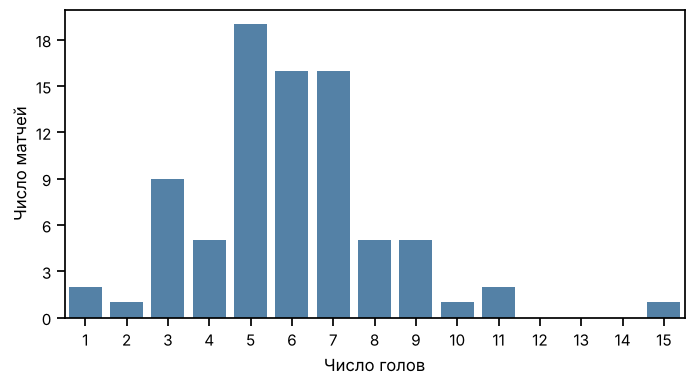

In [8]:
plt.figure(figsize=(8, 4))
sns.countplot(x=games['Total Score'], order=range(1, 16), color='steelblue')
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.yticks(range(0, 21, 3))
plt.show()

In [9]:
print(games['Total Score'].value_counts().sort_index())

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64


**Комментарий.** Распределение в целом одномодальное (есть небольшой всплеск на 3 голах — 9 матчей), чаще всего в матче забивали 5 голов (19 игр), чуть реже 6 и 7 (по 16 игр). Распределение немного скошено вправо: слева значения ограничены (меньше 1 гола в плей-офф не бывает, так как играют до победы), а справа есть длинный хвост — матчи с 10, 11 и даже 15 голами. Матч с 15 голами — явный выброс. В целом картина похожа на распределение Пуассона, которое часто используют для моделирования числа голов.

## Пункт 6

In [10]:
# игр с минимальным/максимальным числом голов может быть несколько, поэтому берём все
min_score = games['Total Score'].min()
max_score = games['Total Score'].max()

least = [gameInfo(i) for i in games[games['Total Score'] == min_score].index]
most = [gameInfo(i) for i in games[games['Total Score'] == max_score].index]

print(least)
print(most)

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Самые нерезультативные игры закончились со счётом 1:0, и обе в овертайме — то есть в основное время голов не было вообще. Самая результативная игра — Колорадо против Миннесоты, 9:6.

## Пункт 7

Берём все столбцы с игроками на льду (по 6 у каждой команды) и вратарей. Для каждой игры собираем множество фамилий и считаем его размер. Пропуски (`NaN`) не считаем: они появляются, например, когда вратаря снимают ради шестого полевого и в поле вратаря ничего нет.

In [11]:
# столбцы с игроками на льду обеих команд и вратарями
player_cols = []
for c in events.columns:
    if 'Player on the Ice' in c or 'Goalie' in c:
        player_cols.append(c)
print(player_cols)

# для каждой игры собираем множество всех фамилий (set убирает повторы)
player_count = {}
for gid, df in events.groupby('Game ID'):
    players = set()
    for c in player_cols:
        for p in df[c].dropna():
            players.add(p)
    player_count[gid] = len(players)

games['Player Count'] = pd.Series(player_count)

["Away Team's Player on the Ice #1", "Away Team's Player on the Ice #2", "Away Team's Player on the Ice #3", "Away Team's Player on the Ice #4", "Away Team's Player on the Ice #5", "Away Team's Player on the Ice #6", "Away Team's Goalie", "Home Team's Player on the Ice #1", "Home Team's Player on the Ice #2", "Home Team's Player on the Ice #3", "Home Team's Player on the Ice #4", "Home Team's Player on the Ice #5", "Home Team's Player on the Ice #6", "Home Team's Goalie"]


In [12]:
games['Game Info'] = [gameInfo(i) for i in games.index]

max_players = games['Player Count'].max()
print(games[games['Player Count'] == max_players][['Game Info', 'Player Count']])

                                                    Game Info  Player Count
Game ID                                                                    
2025030216  Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...            40


In [13]:
print(games['Player Count'].value_counts().sort_index())

Player Count
38    73
39     8
40     1
Name: count, dtype: int64


Больше всего игроков (40) участвовало в матче Монреаль — Баффало (3:8). В обычной игре участвуют 38 человек: в заявку команды входят 18 полевых игроков и 2 вратаря, но запасной вратарь обычно не выходит на лёд. 40 игроков получается, если обе команды меняли вратаря по ходу игры. При счёте 3:8 это вполне логично.

Замечание: в примере в задании указано 41. Такое число получится, если считать `NaN` (пустое поле вратаря) как отдельного «игрока». Мы пропуски не учитываем, поэтому у нас 40.

## Пункт 8

Сначала определяем, в какие ворота бьёт команда. Если ворота хозяев слева (`left`), то хозяева атакуют правые ворота ($X = 89$), а гости — левые ($X = -89$). Если справа (`right`) — наоборот. Затем считаем расстояние до ближайшей точки створа по формуле из задания:

$$
d(x, y) =
\begin{cases}
\sqrt{(x - X)^2 + (y + 3)^2}, & y < -3,\\
|x - X|, & -3 \le y \le 3,\\
\sqrt{(x - X)^2 + (y - 3)^2}, & y > 3,
\end{cases}
$$

где $(x, y)$ — координаты броска в футах, $X$ — координата линии ворот, а $\pm 3$ — штанги (ширина ворот 6 футов).

In [14]:
# расстояние от точки броска до ближайшей точки створа ворот, в которые бьёт команда
def shot_length(row):
    x = row['X Coordinate on the Ice Rink']
    y = row['Y Coordinate on the Ice Rink']
    home_shoots = (row['Team Making the Play'] == row['Home Team'])

    # определяем, в какие ворота бьют: хозяева атакуют ворота на противоположной стороне от своих
    if row["Home Team's Defending Side"] == 'left':
        if home_shoots:
            X = 89
        else:
            X = -89
    else:
        if home_shoots:
            X = -89
        else:
            X = 89

    # формула из задания: ворота - отрезок от y = -3 до y = 3
    if y < -3:
        return np.sqrt((x - X)**2 + (y + 3)**2)
    elif y <= 3:
        return abs(x - X)
    else:
        return np.sqrt((x - X)**2 + (y - 3)**2)

# считаем расстояние только для бросков, у остальных событий будет NaN
is_shot = events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])
events.loc[is_shot, 'Shot Length'] = events[is_shot].apply(shot_length, axis=1)

print(events[is_shot][['Game ID', 'Play Type', 'Shot Length']])

          Game ID     Play Type  Shot Length
7      2025030111   missed-shot       12.207
9      2025030111   missed-shot       12.000
12     2025030111   missed-shot       29.411
13     2025030111  shot-on-goal       62.169
19     2025030111   missed-shot       52.924
...           ...           ...          ...
29695  2025030416   missed-shot       54.083
29696  2025030416   missed-shot        5.099
29704  2025030416          goal       46.239
29706  2025030416   missed-shot       60.926
29707  2025030416  shot-on-goal       49.041

[7266 rows x 3 columns]


In [15]:
print(events.loc[is_shot, 'Shot Length'].describe())

count   7266.000
mean      35.409
std       27.471
min        0.000
25%       15.556
50%       31.898
75%       47.877
max      188.215
Name: Shot Length, dtype: float64


Получилось 7 266 бросков, значения совпадают с примером. Пропусков в расстоянии нет. Средняя дистанция броска около 35 футов (чуть больше 10 метров), медиана около 32 футов. Есть и броски со своей половины площадки (больше 100 футов).

## Пункт 9

Делим броски на точные (`shot-on-goal` и `goal`) и неточные (`missed-shot`). Подвыборки разного размера, поэтому строим не количество, а плотность (`stat='density'`) и нормируем каждую группу отдельно (`common_norm=False`). Тогда площадь под каждой гистограммой равна 1 и их можно сравнивать.

In [16]:
# отдельная таблица бросков с меткой: точный (on goal) или неточный (missed)
shots = events[is_shot].copy()
shots['Shot'] = 'missed'
shots.loc[shots['Play Type'].isin(['shot-on-goal', 'goal']), 'Shot'] = 'on goal'

print(shots['Shot'].value_counts())

Shot
on goal    4623
missed     2643
Name: count, dtype: int64


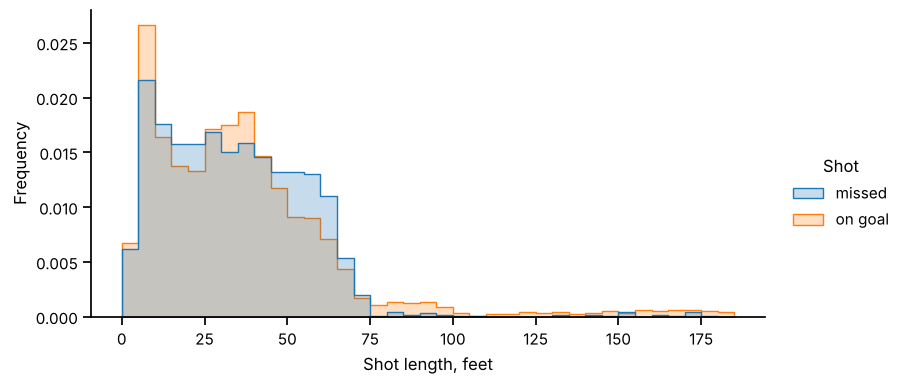

In [17]:
# stat='density' и common_norm=False - каждая группа нормируется отдельно,
# поэтому разный размер подвыборок не мешает сравнению
sns.displot(data=shots, x='Shot Length', hue='Shot',
            stat='density', common_norm=False,
            bins=range(0, 190, 5), element='step',
            height=4, aspect=2)
plt.xlabel('Shot length, feet')
plt.ylabel('Frequency')
plt.show()

In [18]:
print(shots.groupby('Shot')['Shot Length'].describe())

           count   mean    std    min    25%    50%    75%     max
Shot                                                              
missed  2643.000 34.014 22.313  0.000 16.155 32.249 49.041 185.068
on goal 4623.000 36.207 29.997  0.000 15.000 31.828 47.011 188.215


**Вывод.** Распределения похожи по форме: основная масса бросков делается с расстояния до 75 футов, то есть из зоны атаки (синяя линия находится в 64 футах от ворот). Медианы у точных и неточных бросков почти одинаковые (около 32 футов). Но есть различия:
- с очень близкого расстояния (5–10 футов) точных бросков относительно больше — это добивания и броски прямо перед воротами, где промахнуться трудно;
- на средней дистанции 45–70 футов (броски от синей линии) относительно больше неточных: издалека игроки чаще бьют мимо;
- после 75 футов почти все броски точные, получается длинный хвост у оранжевой гистограммы.

**Почему длинный хвост у точных бросков со своей половины?** Дальние броски (больше 89 футов, т. е. из-за центральной линии) почти все идут в створ. Причины:
1. Броски в пустые ворота. В конце матча проигрывающая команда снимает вратаря, и соперник бросает через всю площадку. Такие броски часто точные и часто становятся голами.
2. Выбросы шайбы из зоны. Когда игрок просто выбрасывает шайбу из своей зоны в сторону чужих ворот, а вратарь её ловит, это записывается как бросок в створ. Вратарь такую шайбу берёт легко, но по статистике это «точный бросок». Это видно и по полю `Play Zone`: среди бросков из своей зоны (`Defensive`) почти все записаны как `shot-on-goal` или `goal` (143 из 164).
3. Шайба, которая летит мимо ворот издалека, обычно не фиксируется как бросок вообще — это скорее просто проброс. Поэтому неточных дальних бросков в данных мало.

## Пункт 10

Незаблокированные броски — это `shot-on-goal`, `goal` и `missed-shot` (заблокированные `blocked-shot` не считаем). Для каждой игры и команды считаем, какая доля из них пришлась в створ.

In [19]:
shots['On Goal'] = (shots['Shot'] == 'on goal')

# sum - число точных бросков (True считается как 1), count - все незаблокированные броски
numshots = shots.groupby(['Game ID', 'Team Making the Play'])['On Goal'].agg(['sum', 'count'])
numshots.columns = ['Shots on Goal', 'All Shots']
numshots['Share of Shots on Goal'] = numshots['Shots on Goal'] / numshots['All Shots']

print(numshots['Share of Shots on Goal'])

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64


In [20]:
print(numshots['Share of Shots on Goal'].describe())

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860
Name: Share of Shots on Goal, dtype: float64


**Вывод.** В среднем около 64% незаблокированных бросков команды попадают в створ ворот. Разброс между матчами довольно большой: от 35% до 86%, стандартное отклонение около 8.5 п. п. То есть точность бросков сильно меняется от игры к игре, и по одной игре сложно судить о том, какая команда бросает лучше. Для сравнения команд лучше усреднить долю по всем матчам (следующий пункт).

## Пункт 11

In [21]:
# усредняем долю точных бросков по всем матчам команды
avgnumshots = numshots.groupby(level='Team Making the Play')['Share of Shots on Goal'].mean()

print(avgnumshots.nlargest(5))
print(avgnumshots.nsmallest(5))

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


In [22]:
# число матчей каждой команды: сколько раз она встречается среди гостей и хозяев
team_games = pd.concat([games['Away Team'], games['Home Team']]).value_counts()
print(team_games)

Vegas Golden Knights    22
Montréal Canadiens      19
Carolina Hurricanes     19
Buffalo Sabres          13
Colorado Avalanche      13
Anaheim Ducks           12
Minnesota Wild          11
Philadelphia Flyers     10
Tampa Bay Lightning      7
Boston Bruins            6
Pittsburgh Penguins      6
Dallas Stars             6
Utah Mammoth             6
Edmonton Oilers          6
Ottawa Senators          4
Los Angeles Kings        4
Name: count, dtype: int64


**Комментарий.** Самая высокая средняя точность у Эдмонтона (около 71%), самая низкая — у Питтсбурга (около 55%). Разница между лучшими и худшими командами — порядка 10–15 процентных пунктов.

Связи с успехом в плей-офф здесь почти не видно. Эдмонтон и Филадельфия, у которых точность выше всех, сыграли всего по 6 и 10 матчей. А Каролина, которая дошла до финала (19 матчей), находится среди команд с низкой долей точных бросков. Кроме того, у команд, сыгравших 6 матчей, среднее считается по маленькой выборке, поэтому оно менее надёжно. Видимо, важна не только доля точных бросков, но и их количество и качество (откуда бросают).

## Пункт 12

Броски в створ — это `shot-on-goal` и `goal` (гол — это тоже бросок в створ, который вратарь не отбил; так считают и в официальной статистике НХЛ). Делим общее число бросков и голов команды на число сыгранных ею матчей (посчитано выше в `team_games`).

In [23]:
# броски в створ = отбитые вратарём + голы
on_goal = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
team_shots = on_goal.groupby('Team Making the Play').size()
team_goals = events[events['Play Type'] == 'goal'].groupby('Team Making the Play').size()

# делим на число матчей команды (индексы совпадают - названия команд)
avgshots = pd.DataFrame({'Shot': team_shots / team_games,
                         'Goal': team_goals / team_games})
avgshots.index.name = 'Team Making the Play'

print(avgshots)

                       Shot   Goal
Team Making the Play              
Anaheim Ducks        31.667  3.250
Boston Bruins        25.167  2.000
Buffalo Sabres       30.462  3.308
Carolina Hurricanes  31.632  3.474
Colorado Avalanche   32.154  3.385
Dallas Stars         31.000  2.500
Edmonton Oilers      28.333  3.500
Los Angeles Kings    25.250  1.250
Minnesota Wild       28.727  3.727
Montréal Canadiens   23.263  2.842
Ottawa Senators      27.500  1.250
Philadelphia Flyers  24.600  2.100
Pittsburgh Penguins  26.500  1.833
Tampa Bay Lightning  28.000  2.143
Utah Mammoth         27.833  3.000
Vegas Golden Knights 26.545  3.455


Больше всего бросков в створ за игру у Колорадо (32.2), меньше всего у Монреаля (23.3). Больше всего голов за игру у Миннесоты (3.7), меньше всего у Лос-Анджелеса и Оттавы (1.25).

## Пункт 13

Подписываем на графике несколько команд с крайними значениями (по две с наибольшим и наименьшим числом бросков и голов).

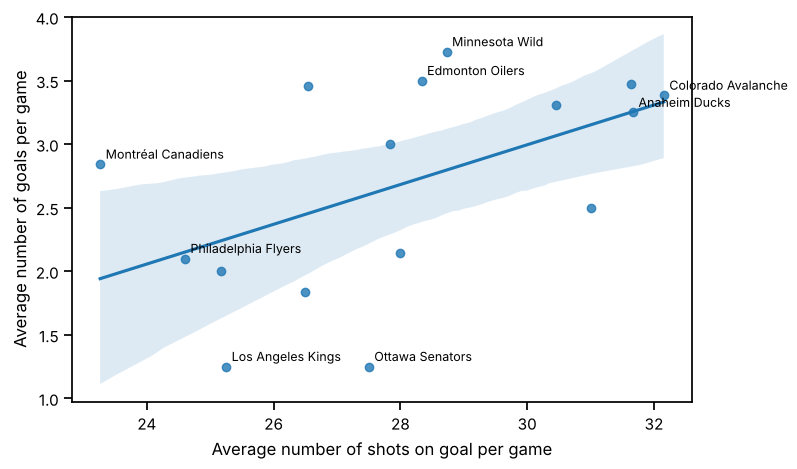

In [24]:
plt.figure(figsize=(8, 5))
sns.regplot(x='Shot', y='Goal', data=avgshots)

# подписываем команды с крайними значениями, чтобы не загромождать график
label_teams = set()
for col in ['Shot', 'Goal']:
    for t in avgshots[col].nlargest(2).index:
        label_teams.add(t)
    for t in avgshots[col].nsmallest(2).index:
        label_teams.add(t)

for t in label_teams:
    plt.annotate(t, (avgshots.loc[t, 'Shot'], avgshots.loc[t, 'Goal']),
                 fontsize=9, xytext=(4, 4), textcoords='offset points')

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.show()

In [25]:
print(avgshots.corr())

       Shot   Goal
Shot  1.000  0.521
Goal  0.521  1.000


**Вывод.** Связь есть, но слабая. Линия регрессии идёт вверх (команды, которые больше бросают, в среднем больше забивают), корреляция около 0.5. Но доверительный интервал широкий, а точек всего 16. Есть заметные исключения: Монреаль бросал меньше всех (23.3), но забивал 2.8 гола за игру, примерно как средняя команда. Даллас, наоборот, бросал много (31 бросок), а забивал всего 2.5. Оттава при средних 27.5 бросках забивала только 1.25 гола. Значит, число голов зависит не только от количества бросков, но и от их качества и от игры вратаря соперника.

## Пункт 14

Считаем все удары: `shot-on-goal`, `goal`, `missed-shot` и `blocked-shot`.

In [26]:
# все удары, включая заблокированные
all_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]
shots_per_game = all_shots.groupby('Game ID').size()

idxmax = shots_per_game.idxmax()
print(shots_per_game.max())
print(gameInfo(idxmax))

208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Больше всего ударов (208) было в матче Каролина — Оттава, который шёл два овертайма, т. е. почти пять периодов. Поэтому и бросков так много.

## Пункт 15

Чтобы гости всегда били в левые ворота, а хозяева в правые, нужно отразить координаты $(x, y) \mapsto (-x, -y)$ в тех периодах, где ворота хозяев находятся справа. Проверим, что в этом матче это как раз нечётные периоды:

In [27]:
game_shots = all_shots[all_shots['Game ID'] == idxmax].copy()
print(game_shots.groupby(['Period', "Home Team's Defending Side"]).size())

Period  Home Team's Defending Side
1       right                         46
2       left                          45
3       right                         40
4       left                          42
5       right                         35
dtype: int64


Да, в периодах 1, 3, 5 ворота хозяев справа, поэтому отражаем координаты в нечётных периодах.

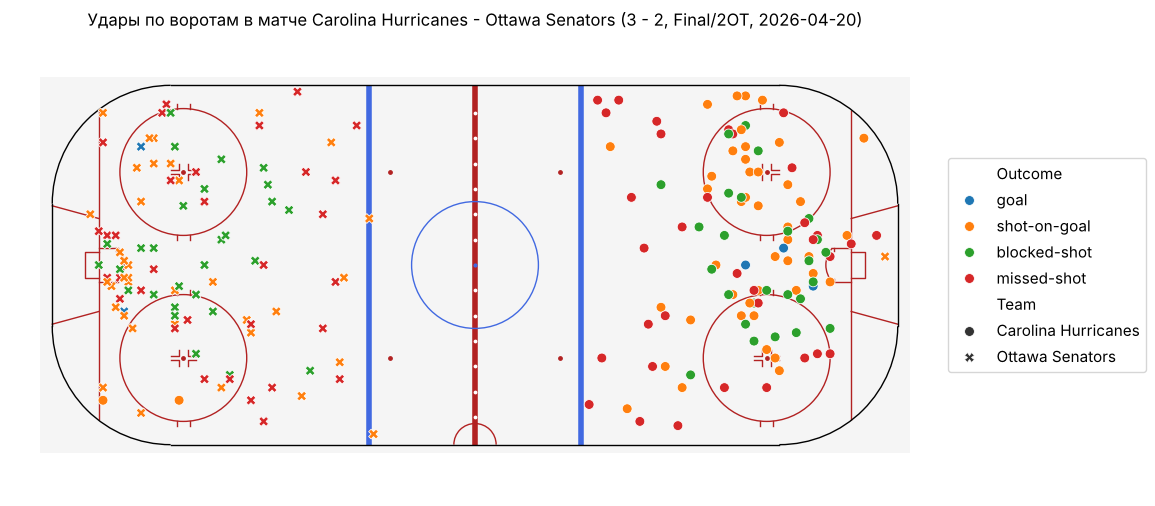

In [28]:
# в нечётных периодах отражаем координаты: (x, y) -> (-x, -y)
odd = (game_shots['Period'] % 2 == 1)
game_shots['x'] = game_shots['X Coordinate on the Ice Rink']
game_shots['y'] = game_shots['Y Coordinate on the Ice Rink']
game_shots.loc[odd, 'x'] = -game_shots.loc[odd, 'x']
game_shots.loc[odd, 'y'] = -game_shots.loc[odd, 'y']

# переименовываем столбцы, чтобы в легенде были короткие подписи
game_shots = game_shots.rename(columns={'Play Type': 'Outcome', 'Team Making the Play': 'Team'})

plt.figure(figsize=(12, 6))
plot_rink()   # сначала рисуем площадку, потом поверх точки ударов
sns.scatterplot(x='x', y='y', data=game_shots, hue='Outcome', style='Team',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                s=50)
plt.axis('equal')
plt.axis('off')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.title('Удары по воротам в матче ' + gameInfo(idxmax))
plt.show()

In [29]:
print(pd.crosstab(game_shots['Team'], game_shots['Outcome']))

Outcome              blocked-shot  goal  missed-shot  shot-on-goal
Team                                                              
Carolina Hurricanes            26     3           34            46
Ottawa Senators                28     2           32            37


**Комментарий.** Матч был довольно равным: у Каролины (хозяева, бьют вправо) 109 ударов, у Оттавы 99. Почти все удары нанесены из зоны атаки, причём больше всего их из района между кругами вбрасывания и прямо перед воротами. Голы забиты с близкого расстояния, из района перед воротами. Заблокированные удары находятся в основном дальше от ворот, ближе к синей линии и в районе кругов — с такого расстояния защитники успевают перекрыть бросок. Несколько оранжевых точек у своих ворот — это выбросы шайбы из своей зоны, которые записаны как броски в створ (см. пункт 9).

## Пункт 16

Для голов `Player in the Event #1` — это автор гола.

In [30]:
# все голы; Player #1 - автор, #2 и #3 - ассистенты
goals = events[events['Play Type'] == 'goal']

top_goals = goals['Player in the Event #1'].value_counts()
print(top_goals.head(10))

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64


In [31]:
# сколько игроков на самом деле делят 10-е место
print(top_goals.nlargest(10, keep='all'))

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Matt Boldy           7
Mark Stone           7
Name: count, dtype: int64


Лучший снайпер плей-офф — Бретт Хауден (14 голов), за ним Павел Дорофеев (12) и Логан Станковен (11). Хауден и Дорофеев играют за Вегас, Станковен за Каролину, т. е. за финалистов, которые сыграли больше всего матчей. На 10-м месте несколько игроков с 7 голами, поэтому список из ровно десяти фамилий немного условный.

## Пункт 17

Передачи — это `Player in the Event #2` (первый ассистент) и `Player in the Event #3` (второй ассистент). Объединяем оба столбца в один и считаем.

In [32]:
# ставим оба столбца ассистентов друг под другом и считаем, сколько раз встречается каждый игрок
assists = pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']])
top_assists = assists.value_counts()

print(top_assists.head(10))

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64


Больше всех голевых передач у Джека Айкела (20) и Митча Марнера (19), оба играют за Вегас.

## Пункт 18

In [33]:
# объединяем голы и передачи; NaN = у игрока нет голов или передач, заменяем на 0
points = pd.DataFrame({'Goals': top_goals, 'Assists': top_assists}).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']

print(points.sort_values('Points', ascending=False).head(10))

                 Goals  Assists  Points
Mitch Marner        10       19      29
Jack Eichel          2       20      22
Jackson Blake        7       13      20
Taylor Hall          7       12      19
Brett Howden        14        4      18
Shea Theodore        6       12      18
Nikolaj Ehlers       8       10      18
Nick Suzuki          4       12      16
Pavel Dorofeyev     12        4      16
Lane Hutson          3       13      16


По системе «гол + пас» лидирует Митч Марнер (29 очков: 10 голов и 19 передач), второй — Джек Айкел (22). У Айкела почти все очки — передачи, а Хауден, наоборот, набрал очки в основном за счёт голов.

## Пункт 19

Число игр для каждого игрока считаем как число матчей, в которых он хотя бы раз был на льду (используем те же столбцы, что в пункте 7). Броски в створ — `shot-on-goal` и `goal`, бросающий игрок — `Player in the Event #1`.

In [34]:
# число сыгранных матчей: в скольких играх игрок хоть раз был на льду
games_played = {}
for gid, df in events.groupby('Game ID'):
    players = set()
    for c in player_cols:
        for p in df[c].dropna():
            players.add(p)
    for p in players:
        games_played[p] = games_played.get(p, 0) + 1

games_played = pd.Series(games_played)
print(games_played.describe())

count   372.000
mean      8.403
std       5.651
min       1.000
25%       4.000
50%       6.000
75%      12.000
max      22.000
dtype: float64


In [35]:
player_shots = on_goal['Player in the Event #1'].value_counts()

# dropna убирает игроков без бросков
shots_pg = pd.DataFrame({'Shots': player_shots, 'Games': games_played}).dropna()
shots_pg['Shots per Game'] = shots_pg['Shots'] / shots_pg['Games']

print(shots_pg.sort_values('Shots per Game', ascending=False).head(10))

                  Shots  Games  Shots per Game
Jason Robertson  30.000      6           5.000
Dylan Guenther   27.000      6           4.500
Nikita Kucherov  31.000      7           4.429
Matt Boldy       48.000     11           4.364
Quinton Byfield  17.000      4           4.250
Darren Raddysh   28.000      7           4.000
Joel Eriksson Ek 24.000      6           4.000
Alex Laferriere  15.000      4           3.750
David Pastrnak   22.000      6           3.667
Nathan MacKinnon 47.000     13           3.615


Больше всего бросков в створ за игру у Джейсона Робертсона (5 бросков за игру). Видно, что вверху списка много игроков, сыгравших всего 4–7 матчей (команды, вылетевшие в первом раунде). Если оставить только тех, кто сыграл хотя бы 10 игр, список меняется:

In [36]:
# только игроки, сыгравшие не меньше 10 матчей
print(shots_pg[shots_pg['Games'] >= 10].sort_values('Shots per Game', ascending=False).head(10))

                  Shots  Games  Shots per Game
Matt Boldy       48.000     11           4.364
Nathan MacKinnon 47.000     13           3.615
Rasmus Dahlin    46.000     13           3.538
Alex Tuch        46.000     13           3.538
Tage Thompson    46.000     13           3.538
Leo Carlsson     41.000     12           3.417
Cutter Gauthier  39.000     12           3.250
Ryan Hartman     35.000     11           3.182
Logan Stankoven  55.000     19           2.895
Taylor Hall      55.000     19           2.895


## Пункт 20

In [37]:
# силовые приёмы; Player #1 - кто провёл приём
hits = events[events['Play Type'] == 'hit']
player_hits = hits['Player in the Event #1'].value_counts()

hits_pg = pd.DataFrame({'Hits': player_hits, 'Games': games_played}).dropna()
hits_pg['Hits per Game'] = hits_pg['Hits'] / hits_pg['Games']

print(hits_pg.sort_values('Hits per Game', ascending=False).head(10))

                      Hits  Games  Hits per Game
Lawson Crouse       38.000      6          6.333
Alexander Petrovic   6.000      1          6.000
Alex Turcotte        6.000      1          6.000
Yakov Trenin        51.000      9          5.667
Dylan Cozens        22.000      4          5.500
Vasily Podkolzin    32.000      6          5.333
Ivan Barbashev     110.000     22          5.000
Carl Grundstrom     15.000      3          5.000
Marcus Foligno      55.000     11          5.000
Owen Tippett        29.000      6          4.833


Первое место у Лоусона Круза (6.3 силовых приёма за игру). Но здесь в топ попадают и игроки, сыгравшие всего один матч (Петрович, Туркотт), для них среднее ничего не значит. С ограничением «хотя бы 10 игр»:

In [38]:
# только игроки, сыгравшие не меньше 10 матчей
print(hits_pg[hits_pg['Games'] >= 10].sort_values('Hits per Game', ascending=False).head(10))

                        Hits  Games  Hits per Game
Ivan Barbashev       110.000     22          5.000
Marcus Foligno        55.000     11          5.000
William Carrier       91.000     19          4.789
Cole Smith           100.000     22          4.545
Jordan Staal          86.000     19          4.526
Jeffrey Truchon-Viel  51.000     12          4.250
Travis Konecny        41.000     10          4.100
Tim Washe             48.000     12          4.000
Keegan Kolesar        82.000     21          3.905
Andrei Svechnikov     74.000     19          3.895


Среди игроков, сыгравших много матчей, лидируют Иван Барбашёв (110 силовых приёмов за 22 игры, т. е. 5 за игру), Маркус Фолиньо и Уильям Карриер.

## Пункт 21

Для каждой игры смотрим, какие вратари выходили на лёд (поля `Away Team's Goalie` и `Home Team's Goalie`). Потом проходим по всем голам: если забили хозяева, то пропустил вратарь гостей, который был на льду в этот момент, и наоборот. Если в момент гола вратаря на льду не было (пустые ворота), то этот гол никому из вратарей не записываем. Вратарь «на ноль» — тот, кто был на льду в игре, но не пропустил ни одного гола.

**Важная проблема в данных.** Сначала я сделал так и получил, что в обоих матчах 1:0 «на ноль» сыграли оба вратаря, чего быть не может. Оказалось, что у голов в овертайме (победных) поля с игроками на льду не заполнены: число игроков обеих команд равно 0, вратарей нет. Проверим:

In [39]:
# голы, у которых не указан ни один игрок на льду
goal_rows = events[events['Play Type'] == 'goal']
no_players = goal_rows[(goal_rows["# of Away Team's Players on the Ice"] == 0) &
                       (goal_rows["# of Home Team's Players on the Ice"] == 0)]
print(len(no_players))
print(no_players['Period'].value_counts())

22
Period
4    18
5     4
Name: count, dtype: int64


Таких голов 22, и все они в овертаймах. Поэтому для них берём вратаря из последнего предыдущего события в этой игре, где он указан (вратарь в овертайме обычно не меняется). А если игроки на льду указаны, но поле вратаря пустое — это настоящие пустые ворота.

In [40]:
shutouts = []

for gid, df in events.groupby('Game ID'):
    home = df['Home Team'].iloc[0]

    # все вратари, которые выходили на лёд в этой игре
    goalies = set()
    for c in ["Home Team's Goalie", "Away Team's Goalie"]:
        for g in df[c].dropna():
            goalies.add(g)

    # вратари, которые пропустили хотя бы один гол
    conceded = set()
    for i, row in df[df['Play Type'] == 'goal'].iterrows():
        # гол пропускает вратарь команды, которая не забивала
        if row['Team Making the Play'] == home:
            col = "Away Team's Goalie"
        else:
            col = "Home Team's Goalie"

        if row["# of Away Team's Players on the Ice"] == 0 and row["# of Home Team's Players on the Ice"] == 0:
            # данных об игроках нет (гол в овертайме) - берём последнего известного вратаря
            g = df.loc[:i, col].dropna().iloc[-1]
        else:
            g = row[col]

        if pd.notna(g):
            conceded.add(g)

    # «на ноль» - выходил на лёд, но не пропустил
    for g in goalies:
        if g not in conceded:
            shutouts.append([g, gameInfo(gid)])

shutouts = pd.DataFrame(shutouts, columns=['Goalie', 'Game'])
print(shutouts.to_string())

               Goalie                                                                     Game
0    Joonas Korpisalo                Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)
1  Andrei Vasilevskiy   Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
2   Frederik Andersen         Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)
3          Dan Vladar     Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)
4          Dan Vladar  Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
5   Frederik Andersen     Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)
6     Scott Wedgewood        Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)
7   Frederik Andersen      Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)
8       Brandon Bussi    Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


In [41]:
print(sorted(shutouts['Goalie'].unique()))
print(len(shutouts['Goalie'].unique()))

['Andrei Vasilevskiy', 'Brandon Bussi', 'Dan Vladar', 'Frederik Andersen', 'Joonas Korpisalo', 'Scott Wedgewood']
6


Всего 6 вратарей хотя бы раз не пропустили ни одного гола: Фредерик Андерсен (3 раза), Дэн Владар (2 раза), Андрей Василевский, Брэндон Бусси (в последнем матче финала), Йонас Корписало и Скотт Уэджвуд. Два последних случая — неполные матчи: команда Корписало проиграла 1:6, а команда Уэджвуда выиграла 4:3 в овертайме, т. е. пропустила 3 гола. Значит, они выходили на замену и в своё время на льду голов не пропустили. В матчах 1:0 теперь «на ноль» только по одному вратарю, как и должно быть.

Без исправления с овертаймами получилось бы 8 вратарей (лишние — те, кто пропустил только в овертайме), поэтому проверять данные на такие пропуски было важно.

## Пункт 22

**Вопрос:** насколько важно забить первым? Как часто выигрывает команда, открывшая счёт, и есть ли в плей-офф преимущество своей площадки?

Для каждой игры находим команду, забившую первый гол (первая строка с `goal` в игре), и победителя.

In [42]:
# события идут по порядку, поэтому первый гол в игре - первая строка с goal
first_goal = goals.groupby('Game ID')['Team Making the Play'].first()

# победитель - команда с большим числом голов (ничьих в плей-офф нет)
winner = []
for gid in games.index:
    if games.loc[gid, 'Home Score'] > games.loc[gid, 'Away Score']:
        winner.append(games.loc[gid, 'Home Team'])
    else:
        winner.append(games.loc[gid, 'Away Team'])
games['Winner'] = winner
games['First Goal'] = first_goal

games['First Scorer Won'] = (games['First Goal'] == games['Winner'])
games['Home Won'] = (games['Winner'] == games['Home Team'])

print('Доля побед команды, забившей первой:', round(games['First Scorer Won'].mean(), 3))
print('Доля побед хозяев:', round(games['Home Won'].mean(), 3))

Доля побед команды, забившей первой: 0.683
Доля побед хозяев: 0.476


In [43]:
print(games.groupby('Outcome')['First Scorer Won'].agg(['mean', 'count']))

            mean  count
Outcome                
Final      0.733     60
Final/2OT  0.750      4
Final/OT   0.500     18


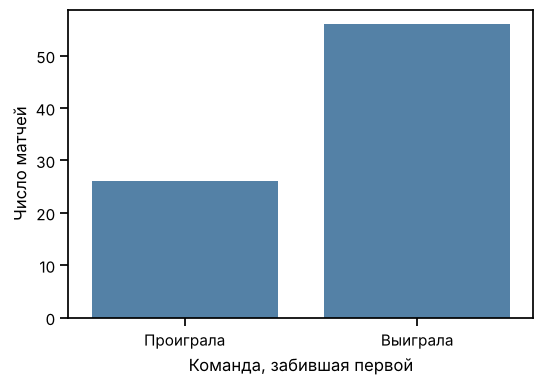

In [44]:
plt.figure(figsize=(6, 4))
sns.countplot(x='First Scorer Won', data=games, color='steelblue')
plt.xticks([0, 1], ['Проиграла', 'Выиграла'])
plt.xlabel('Команда, забившая первой')
plt.ylabel('Число матчей')
plt.show()

**Ответ.** Команда, которая забила первой, выигрывала в 56 матчах из 82, т. е. примерно в 68% случаев. Это заметно больше 50%, значит первый гол действительно даёт большое преимущество (дальше соперник вынужден раскрываться и атаковать). В матчах, закончившихся в основное время, эта доля ещё выше (73%). А в матчах с одним овертаймом ровно 50%: раз игра дошла до овертайма, соперник уже сравнял счёт, и преимущество первого гола пропадает. Матчей с двумя овертаймами всего 4, по ним выводы делать нельзя.

А вот преимущества своей площадки в этом плей-офф не видно: хозяева выиграли только 47.6% матчей, т. е. даже меньше половины. Так что для победы гораздо важнее открыть счёт, чем играть дома.

## Итоги

| Пункт | Результат |
|---|---|
| 1 | Данные: 29 710 событий, 38 полей |
| 2 | 82 игры: 60 в основное время, 18 с одним овертаймом, 4 с двумя |
| 3 | Функция `gameInfo()` выводит описание игры |
| 4–5 | В среднем 5.9 гола за матч (медиана 6), чаще всего 5 голов; распределение скошено вправо, есть выброс на 15 голах |
| 6 | Меньше всего голов: два матча 1:0 в овертайме; больше всего: Колорадо — Миннесота 9:6 |
| 7 | Больше всего игроков (40): Монреаль — Баффало 3:8, обе команды меняли вратаря. В примере 41, потому что там посчитан NaN |
| 8–9 | Медиана дистанции броска около 32 футов у точных и неточных бросков. Длинный хвост точных бросков из своей зоны — броски в пустые ворота и выбросы шайбы, которые записываются как броски в створ |
| 10–11 | В створ попадает около 64% незаблокированных бросков; лучшая точность у Эдмонтона (71%), худшая у Питтсбурга (55%); с успехом в плей-офф точность почти не связана |
| 12–13 | Связь между бросками и голами положительная, но слабая (корреляция 0.52 по 16 командам) |
| 14–15 | Больше всего ударов (208): Каролина — Оттава, два овертайма; голы забиты с близкого расстояния |
| 16–18 | Лучший снайпер: Хауден (14), лучший ассистент: Айкел (20), больше всего очков у Марнера (29) |
| 19–20 | Больше всего бросков за игру у Робертсона (5.0), силовых приёмов у Круза (6.3); среди сыгравших не меньше 10 матчей — Болди (4.4) и Барбашёв (5.0) |
| 21 | 6 вратарей хотя бы раз не пропустили; в данных нет игроков на льду у голов в овертайме, это пришлось учесть |
| 22 | Команда, забившая первой, выигрывает в 68% матчей; преимущества своей площадки нет (хозяева выиграли 47.6%) |